In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

d = pd.read_csv("../data/model_data.csv")
print(d.shape)
d["log_value"] = np.log(d["market_value_in_eur"])
d[["market_value_in_eur", "log_value", "age", "Minutes"]].describe()

Matplotlib is building the font cache; this may take a moment.


(292, 55)


,market_value_in_eur,log_value,age,Minutes
count,2.920000e+02,292.000000,292.000000,292.000000
mean,2.999640e+07,16.864751,26.820890,2081.609589
std,2.435324e+07,0.961445,3.761846,696.844531
min,5.000000e+05,13.122363,18.700000,911.000000
25%,1.375000e+07,16.436041,24.100000,1509.000000
50%,2.500000e+07,17.034386,26.450000,2041.500000
75%,4.000000e+07,17.504390,28.825000,2612.750000
max,1.800000e+08,19.008467,39.900000,3420.000000


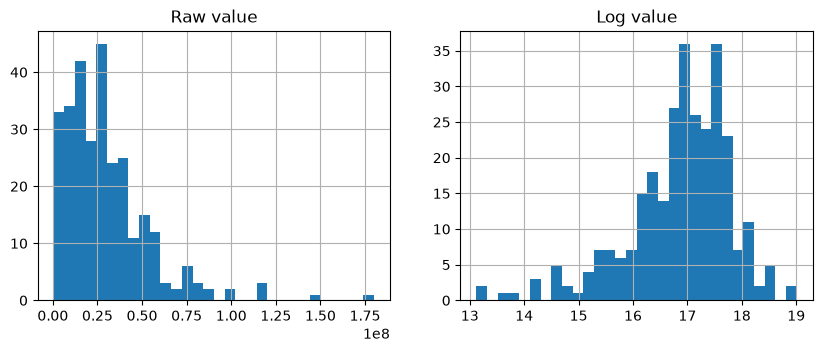

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
d["market_value_in_eur"].hist(bins=30, ax=ax[0]); ax[0].set_title("Raw value")
d["log_value"].hist(bins=30, ax=ax[1]); ax[1].set_title("Log value")
plt.show()

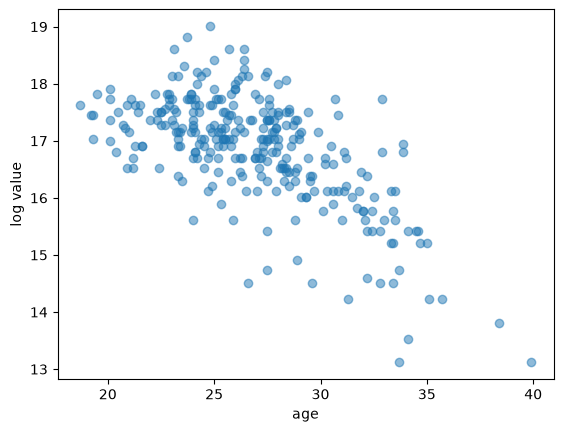

-0.6410761944176786


In [3]:
plt.scatter(d["age"], d["log_value"], alpha=0.5)
plt.xlabel("age"); plt.ylabel("log value"); plt.show()
print(d["age"].corr(d["log_value"]))

In [4]:
num = d.select_dtypes("number").drop(columns=["market_value_in_eur", "days_old"])
corr = num.corr()["log_value"].drop("log_value").sort_values(ascending=False)
print(corr.head(12))
print(corr.tail(8))

Shots_p90                        0.334543
Appearances                      0.300770
Goals_p90                        0.294824
Minutes                          0.289375
Dispossessed_p90                 0.284482
Assists_p90                      0.253300
Big Chances Missed_p90           0.216532
Clean Sheets_p90                 0.211085
Hit Woodwork_p90                 0.178653
Offsides_p90                     0.120494
Carries Ended with Goal_p90      0.113574
Carries Ended with Assist_p90    0.103803
Name: log_value, dtype: float64
aDuels Won_p90      -0.157908
Aerial Duels_p90    -0.159630
Interceptions_p90   -0.161638
Yellow Cards_p90    -0.162587
Blocks_p90          -0.174562
Own Goals_p90       -0.203838
Clearances_p90      -0.246643
age                 -0.641076
Name: log_value, dtype: float64


          count      median          mean
Position                                 
DEF         117  23000000.0  2.482863e+07
FWD          36  31000000.0  3.697222e+07
MID         139  25000000.0  3.253957e+07


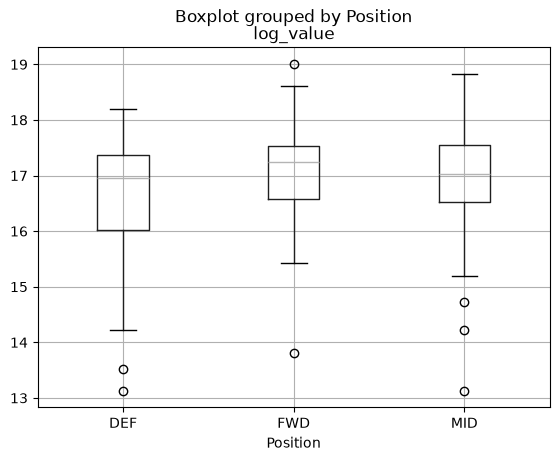

In [5]:
print(d.groupby("Position")["market_value_in_eur"].agg(["count", "median", "mean"]))
d.boxplot(column="log_value", by="Position"); plt.show()

In [6]:
d["age_group"] = pd.cut(d["age"], bins=[18, 21, 23, 25, 27, 29, 31, 40])
print(d.groupby("age_group", observed=True).agg(
    players=("log_value", "size"),
    median_value=("market_value_in_eur", "median"),
    mean_log=("log_value", "mean")))

           players  median_value   mean_log
age_group                                  
(18, 21]        16    36500000.0  17.343403
(21, 23]        26    40000000.0  17.398812
(23, 25]        57    32000000.0  17.352013
(25, 27]        57    28000000.0  17.174707
(27, 29]        68    25000000.0  16.937915
(29, 31]        24    12500000.0  16.409133
(31, 40]        44     6000000.0  15.477803


In [7]:
for pos in ["FWD", "MID", "DEF"]:
    sub = d[d["Position"] == pos]
    c = (sub.select_dtypes("number").drop(columns=["market_value_in_eur", "days_old"])
            .corr()["log_value"].drop("log_value").sort_values(ascending=False))
    print(pos, len(sub)); print(c.head(6)); print(c.tail(4)); print()

FWD 36
Clean Sheets_p90     0.444605
Goals_p90            0.310680
Shots_p90            0.275447
Assists_p90          0.211497
Touches_p90          0.204451
Through Balls_p90    0.191442
Name: log_value, dtype: float64
Blocks_p90         -0.319265
aDuels Won_p90     -0.352647
Aerial Duels_p90   -0.354480
age                -0.665684
Name: log_value, dtype: float64

MID 139
Shots_p90           0.356902
Goals_p90           0.324907
Assists_p90         0.296838
Minutes             0.263713
Dispossessed_p90    0.260105
Offsides_p90        0.237828
Name: log_value, dtype: float64
aDuels Won_p90     -0.191735
Yellow Cards_p90   -0.255295
Clearances_p90     -0.258607
age                -0.540037
Name: log_value, dtype: float64

DEF 117
Minutes                   0.413223
Appearances               0.384577
Clean Sheets_p90          0.329799
Shots_p90                 0.323567
Touches_p90               0.292122
Big Chances Missed_p90    0.245680
Name: log_value, dtype: float64
Passes_p90         

In [8]:
print(d.groupby("Club")["market_value_in_eur"].median().sort_values(ascending=False))

Club
Liverpool                  60000000.0
Arsenal                    55000000.0
Manchester City            40000000.0
Tottenham Hotspur          38000000.0
Manchester United          38000000.0
Newcastle United           35000000.0
Chelsea                    35000000.0
Aston Villa                32000000.0
Brighton & Hove Albion     26500000.0
Bournemouth                25000000.0
Crystal Palace             25000000.0
Nottingham Forest          23500000.0
Brentford                  22000000.0
West Ham United            21000000.0
Wolverhampton Wanderers    18000000.0
Fulham                     18000000.0
Everton                    18000000.0
Ipswich Town               12000000.0
Southampton                12000000.0
Leicester City             10000000.0
Name: market_value_in_eur, dtype: float64
